In [1]:
x=1

In [34]:
import scanpy as sc
import multimil as mtm
import numpy as np


In [47]:
adata = sc.read('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/multigrate_mil/imc_grade/df81fb9f2d_adata_analysis_annotated.h5ad')
adata

AnnData object with n_obs × n_vars = 374964 × 38
    obs: 'id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmonth', 'Comment', 'ER+DuctalCa', 'TripleNegDuctal', 'hormonesensitive', 'hormonerefractory', 'hormoneresistantaftersenstive', 'Fulvestran', 'microinvasion', 'I_plus_neg', 'SN', 'MIC', 'Count_Cells', 'FileName_FullStack', 'Height_FullStack', 'Width_FullStack', 'area', 'sum_area_cells', 'Subtype', 'HER2', 'ER

In [48]:
mtm.score_top_cells(adata)

In [49]:
adata

AnnData object with n_obs × n_vars = 374964 × 38
    obs: 'id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmonth', 'Comment', 'ER+DuctalCa', 'TripleNegDuctal', 'hormonesensitive', 'hormonerefractory', 'hormoneresistantaftersenstive', 'Fulvestran', 'microinvasion', 'I_plus_neg', 'SN', 'MIC', 'Count_Cells', 'FileName_FullStack', 'Height_FullStack', 'Width_FullStack', 'area', 'sum_area_cells', 'Subtype', 'HER2', 'ER

In [50]:
# Check what columns are available in adata.obs
print("Available columns in adata.obs:")
print(adata.obs.columns.tolist())
print("\nSample of obs data:")
print(adata.obs.head())

Available columns in adata.obs:
['id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmonth', 'Comment', 'ER+DuctalCa', 'TripleNegDuctal', 'hormonesensitive', 'hormonerefractory', 'hormoneresistantaftersenstive', 'Fulvestran', 'microinvasion', 'I_plus_neg', 'SN', 'MIC', 'Count_Cells', 'FileName_FullStack', 'Height_FullStack', 'Width_FullStack', 'area', 'sum_area_cells', 'Subtype', 'HER2', 'ER', 'PR', 'clinical_type',

In [51]:
# Check for columns related to top cells
print("\nColumns containing 'top' or 'score' or 'attn' or 'attention':")
relevant_cols = [col for col in adata.obs.columns if any(keyword in col.lower() for keyword in ['top', 'score', 'attn', 'attention'])]
print(relevant_cols)

# Check for grade column
print("\nColumns containing 'grade':")
grade_cols = [col for col in adata.obs.columns if 'grade' in col.lower()]
print(grade_cols)

# Check for cell type columns
print("\nColumns containing 'cell' or 'type':")
celltype_cols = [col for col in adata.obs.columns if any(keyword in col.lower() for keyword in ['cell', 'type', 'label', 'annotation'])]
print(celltype_cols)


Columns containing 'top' or 'score' or 'attn' or 'attention':
['cell_attn_0', 'cell_attn_1', 'cell_attn_2', 'cell_attn_3', 'cell_attn_4', 'cell_attn', 'top_cell_attn']

Columns containing 'grade':
['grade']

Columns containing 'cell' or 'type':
['tumor_type', 'DonorBlocklabel', 'TMABlocklabel', '%tumorcells', '%normalepithelialcells', '%inflammatorycells', 'Count_Cells', 'sum_area_cells', 'Subtype', 'clinical_type', 'cell_attn_0', 'cell_attn_1', 'cell_attn_2', 'cell_attn_3', 'cell_attn_4', 'cell_attn', 'top_cell_attn']


In [52]:
# Let's check all columns to find cell type information
print("\nAll columns in adata.obs:")
for i, col in enumerate(adata.obs.columns):
    print(f"{i}: {col}")

print("\nUnique values in 'top_cell_attn' column:")
print(adata.obs['top_cell_attn'].unique())

print("\nUnique values in 'grade' column:")
print(adata.obs['grade'].unique())


All columns in adata.obs:
0: id
1: core
2: PID
3: location
4: grade
5: tumor_type
6: tumor_size
7: gender
8: menopausal
9: PTNM_M
10: age
11: Patientstatus
12: treatment
13: PTNM_T
14: DiseaseStage
15: PTNM_N
16: AllSamplesSVSp4.Array
17: TMALocation
18: TMAxlocation
19: yLocation
20: DonorBlocklabel
21: diseasestatus
22: TMABlocklabel
23: UBTMAlocation
24: %tumorcells
25: %normalepithelialcells
26: %stroma
27: %inflammatorycells
28: SupplierPatientID
29: Yearofsamplecollection
30: PrimarySite
31: histology
32: PTNM_Radicality
33: Lymphaticinvasion
34: Venousinvasion
35: ERStatus
36: PRStatus
37: HER2Status
38: Pre-surgeryTx
39: Post-surgeryTx
40: Tag
41: Ptdiagnosis
42: DFSmonth
43: OSmonth
44: Comment
45: ER+DuctalCa
46: TripleNegDuctal
47: hormonesensitive
48: hormonerefractory
49: hormoneresistantaftersenstive
50: Fulvestran
51: microinvasion
52: I_plus_neg
53: SN
54: MIC
55: Count_Cells
56: FileName_FullStack
57: Height_FullStack
58: Width_FullStack
59: area
60: sum_area_cells
61

In [53]:
# Let's examine the cell type information in the top cells
print("Unique cell types in cluster_preprocessed:")
print(adata.obs['cluster_preprocessed'].unique())

print("\nNumber of top cells per grade:")
top_cells_mask = adata.obs['top_cell_attn'] == True
print(adata.obs[top_cells_mask]['grade'].value_counts())

print("\nNumber of top cells per cell type:")
print(adata.obs[top_cells_mask]['cluster_preprocessed'].value_counts())

Unique cell types in cluster_preprocessed:
['stromal cells', 'tumor cells', 'macrophages', 'T cells', 'B cells', 'endothelial', 'T and B cells', NaN]
Categories (7, object): ['B cells', 'T and B cells', 'T cells', 'endothelial', 'macrophages', 'stromal cells', 'tumor cells']

Number of top cells per grade:
grade
3    15874
2    11998
1     9625
Name: count, dtype: int64

Number of top cells per cell type:
cluster_preprocessed
tumor cells      34168
T and B cells      614
stromal cells      553
macrophages        368
T cells            258
B cells            160
endothelial         74
Name: count, dtype: int64
cluster_preprocessed
tumor cells      34168
T and B cells      614
stromal cells      553
macrophages        368
T cells            258
B cells            160
endothelial         74
Name: count, dtype: int64


In [54]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Create a dataframe with top cells only
top_cells_df = adata.obs[adata.obs['top_cell_attn'] == True].copy()

# Create a crosstab to count cell types by grade
celltype_grade_counts = pd.crosstab(top_cells_df['cluster_preprocessed'], 
                                   top_cells_df['grade'])

print("Cell type counts by grade (top cells only):")
print(celltype_grade_counts)

Cell type counts by grade (top cells only):
grade                    1      2      3
cluster_preprocessed                    
B cells                 24     21    115
T and B cells           11     48    555
T cells                 55     23    180
endothelial             10     12     52
macrophages             46    184    138
stromal cells          119    154    280
tumor cells           8121  11493  14554


In [55]:
# Define consistent color palette for all plots
import matplotlib.colors as mcolors

def create_color_palette(adata, cluster_key='cluster_preprocessed'):
    """Create a consistent color palette for all cell types using tab10"""
    unique_celltypes = list(adata.obs[cluster_key].cat.categories)
    
    # Use tab10 color palette - 10 distinct colors
    colors_tab10 = plt.cm.tab10(np.linspace(0, 1, 10))  # tab10 has 10 colors
    
    # If we need more colors, extend with tab20
    if len(unique_celltypes) > 10:
        colors_tab20 = plt.cm.tab20(np.linspace(0, 1, 20))
        all_colors = np.vstack([colors_tab10, colors_tab20[10:]])  # Use tab20 colors 11-20
    else:
        all_colors = colors_tab10
    
    # Create color dictionary
    color_dict = {}
    for i, celltype in enumerate(unique_celltypes):
        color_dict[celltype] = all_colors[i % len(all_colors)]
    
    return color_dict

# Create color palette
CELL_TYPE_COLORS = create_color_palette(adata, 'cluster_preprocessed')
print("Color palette created for cell types:")
for celltype, color in CELL_TYPE_COLORS.items():
    print(f"  {celltype}: {mcolors.to_hex(color)}")

Color palette created for cell types:
  B cells: #1f77b4
  T and B cells: #ff7f0e
  T cells: #2ca02c
  endothelial: #d62728
  macrophages: #9467bd
  stromal cells: #8c564b
  tumor cells: #e377c2


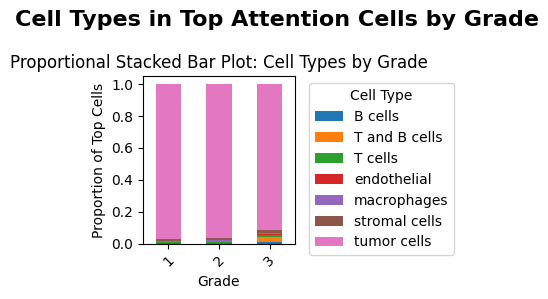


Total number of top cells: 37497
Number of unique cell types in top cells: 7
Number of grades: 3

Top cell types overall:
cluster_preprocessed
tumor cells      34168
T and B cells      614
stromal cells      553
macrophages        368
T cells            258
B cells            160
endothelial         74
Name: count, dtype: int64


In [62]:
# Create proportional stacked bar plot
fig, ax = plt.subplots(1, 1, figsize=(4, 3))
fig.suptitle('Cell Types in Top Attention Cells by Grade', fontsize=16, fontweight='bold')

# Proportional stacked bar plot
celltype_grade_proportions = celltype_grade_counts.div(celltype_grade_counts.sum(axis=0), axis=1)

# Create color list for the plot based on our consistent palette
colors = [CELL_TYPE_COLORS.get(celltype, '#1f77b4') for celltype in celltype_grade_proportions.index]

celltype_grade_proportions.T.plot(kind='bar', ax=ax, stacked=True, color=colors)
ax.set_title('Proportional Stacked Bar Plot: Cell Types by Grade')
ax.set_xlabel('Grade')
ax.set_ylabel('Proportion of Top Cells')
ax.legend(title='Cell Type', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('figures/top_cells_cell_types_by_grade.svg', dpi=300, bbox_inches='tight')
plt.show()

# Print summary statistics
print(f"\nTotal number of top cells: {len(top_cells_df)}")
print(f"Number of unique cell types in top cells: {top_cells_df['cluster_preprocessed'].nunique()}")
print(f"Number of grades: {top_cells_df['grade'].nunique()}")
print(f"\nTop cell types overall:")
print(top_cells_df['cluster_preprocessed'].value_counts().head(10))